In [27]:
import torch
import torch.optim as optim
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset
from torchvision import transforms

# import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import os

In [28]:
device = "cuda"

In [29]:
class ShapeDataset(Dataset):
    def __init__(self, root_dir, subset, transform=None):
        """
        Args:
            root_dir (string): Directory with all the images.
            subset (string): 'train', 'val' or 'test' to specify the subset.
            transform (callable, optional): Optional transform to be applied
                on a sample.
        """
        self.root_dir = root_dir
        self.subset = subset
        self.transform = transform
        
        self.image_paths = []
        self.origin_image_paths = []
        self.labels = []
        self.points = []

        # Load images and labels
        for shape in ['rectangle', 'circle', 'triangle']:
            shape_dir = os.path.join(root_dir, subset, shape)
            for file_name in os.listdir(shape_dir):
                if file_name.endswith('.png') and not file_name.endswith('_origin.png'):
                    self.image_paths.append(os.path.join(shape_dir, file_name))
                    self.origin_image_paths.append(os.path.join(shape_dir, file_name.replace('.png', '_origin.png')))
                    self.labels.append(shape)
                    # Read points from .txt
                    txt_path = os.path.join(shape_dir, file_name.replace('.png', '.txt'))
                    with open(txt_path, 'r') as f:
                        points = f.readlines()
                        points = [point.strip().split() for point in points]
                        points = np.array(points).astype(np.float32)
                        self.points.append(points)
                        
        self.label_to_index = {label: idx for idx, label in enumerate(['rectangle', 'circle', 'triangle'])}
    
    def __len__(self):
        return len(self.image_paths)
    
    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        origin_img_path = self.origin_image_paths[idx]
        image = Image.open(img_path).convert('L')  # Convert image to grayscale
        origin_image = Image.open(origin_img_path).convert('L')  # Convert origin image to grayscale
        label = self.labels[idx]
        label_idx = self.label_to_index[label]
        
        # Get points
        points = self.points[idx]
        
        # Calculate the area as the proportion of white pixels in the origin image
        origin_array = np.array(origin_image)
        area = np.sum(origin_array > 0) / (origin_array.size)
        area = np.array([area]).astype(np.float32)

        if self.transform:
            image = self.transform(image)
            origin_image = self.transform(origin_image)
        
        return image, label_idx, area, points

In [30]:
# Define transforms
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Create dataset instance
train_dataset = ShapeDataset(root_dir='images', subset='train', transform=transform)
val_dataset = ShapeDataset(root_dir='images', subset='val', transform=transform)
test_dataset = ShapeDataset(root_dir='images', subset='test', transform=transform)

# Create dataloaders for training, validation, and test
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64,shuffle=True)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=64,  shuffle=False)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=False)

# Example of getting an item
image, label, area, points = train_dataset[0]
print("Image shape:", image.shape)
print("Label:", label)
print("Area:", area)
print("Points:", points)
print("")
print("Train dataset size:", len(train_dataset))
print("Validation dataset size:", len(val_dataset))
print("Test dataset size:", len(test_dataset))

Image shape: torch.Size([1, 64, 64])
Label: 0
Area: [0.2619629]
Points: [[0.5     0.5    ]
 [0.21875 0.28125]
 [0.78125 0.71875]]

Train dataset size: 7998
Validation dataset size: 1500
Test dataset size: 498


In [31]:
class ShapeModel(nn.Module):
    def __init__(self, num_classes=3):
        super(ShapeModel, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
        self.fc1 = nn.Linear(64 * 16 * 16, 128)
        self.fc2 = nn.Linear(128, 64)
        
        # Output layers
        self.shape_head = nn.Linear(64, num_classes)
        self.area_head = nn.Linear(64, 7)
    
    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 64 * 16 * 16)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        
        shape_out = self.shape_head(x)
        parameter_out = torch.sigmoid(self.area_head(x))
        
        return shape_out, parameter_out

In [32]:
def train(dataloader, model, criterion, optimizer):
    size = len(dataloader.dataset)
    model.train()
    for batch, (X, label, area, points) in enumerate(dataloader):
        X, label, area, points = X.to(device), label.to(device), area.to(device), points.to(device)
            
        # Zero the parameter gradients
        optimizer.zero_grad()
        
        # Forward pass
        shape_outputs, param_outputs = model(X)
        
        # Calculate loss
        param = torch.concatenate([area, points.view(-1, 6)], 1)
        loss_shape = criterion[0](shape_outputs, label)
        loss_param = criterion[1](param_outputs, param.float())
        loss = loss_shape + loss_param
        
        # Backward pass and optimization
        loss.backward()
        optimizer.step()
        
        if batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")
            
def test(dataloader, model, criterion):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, correct = 0, 0
    with torch.no_grad():
        for X, label, area, points in dataloader:
            X, label, area, points = X.to(device), label.to(device), area.to(device), points.to(device)
            shape_outputs, param_outputs = model(X)
            
            # Calculate loss
            param = torch.concatenate([area, points.view(-1, 6)], 1)
            loss_shape = criterion[0](shape_outputs, label)
            loss_param = criterion[1](param_outputs, param.float())
            test_loss = loss_shape + loss_param
            
            correct += (shape_outputs.argmax(1) == label).type(torch.float).sum().item()
    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")

In [33]:
# Initialize the model, loss functions, and optimizer
model = ShapeModel().to(device)
criterion = [nn.CrossEntropyLoss(), nn.MSELoss()]
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 5
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train(train_loader, model, criterion, optimizer)
    test(val_loader, model, criterion)
print("Done!")

Epoch 1
-------------------------------
loss: 1.163537  [   64/ 7998]
loss: 0.112925  [ 6464/ 7998]
Test Error: 
 Accuracy: 97.9%, Avg loss: 0.006846 

Epoch 2
-------------------------------
loss: 0.070897  [   64/ 7998]
loss: 0.116153  [ 6464/ 7998]
Test Error: 
 Accuracy: 94.7%, Avg loss: 0.003553 

Epoch 3
-------------------------------
loss: 0.129851  [   64/ 7998]
loss: 0.062564  [ 6464/ 7998]
Test Error: 
 Accuracy: 99.4%, Avg loss: 0.004683 

Epoch 4
-------------------------------
loss: 0.043087  [   64/ 7998]
loss: 0.038516  [ 6464/ 7998]
Test Error: 
 Accuracy: 99.3%, Avg loss: 0.003364 

Epoch 5
-------------------------------
loss: 0.031206  [   64/ 7998]
loss: 0.018799  [ 6464/ 7998]
Test Error: 
 Accuracy: 99.5%, Avg loss: 0.003204 

Done!


In [34]:
test(test_loader, model, criterion)

Test Error: 
 Accuracy: 99.2%, Avg loss: 0.021336 



In [35]:
# Save the model
torch.save(model.state_dict(), "shape_model_2.pth")

In [36]:
import matplotlib.pyplot as plt
import torch

def visualize_predictions(model, dataset):
    model.eval()
    # Randomly select a batch of images from the dataset
    indices = torch.randint(0, len(dataset), (9,))
    images, labels, areas, points = zip(*[dataset[i] for i in indices])
    images = torch.stack(images).to(device)
    areas = torch.tensor(areas).to(device)

    with torch.no_grad():
        shape_outputs, param_output = model(images)
        _, predicted_shapes = torch.max(shape_outputs, 1)
    
    images = images.cpu()
    labels = torch.tensor(labels).cpu()
    areas = areas.cpu().squeeze()  # Squeeze areas
    predicted_shapes = predicted_shapes.cpu()
    param_output = param_output.cpu().squeeze()  # Squeeze area outputs
    area_output = param_output[:, 0]  # Extract area output from the parameter output

    label_map = {0: 'rectangle', 1: 'circle', 2: 'triangle'}

    plt.figure(figsize=(12, 12))
    for i in range(9):
        plt.subplot(3, 3, i+1)
        plt.imshow(images[i].squeeze(), cmap='gray')
        true_label = label_map[labels[i].item()]
        pred_label = label_map[predicted_shapes[i].item()]
        true_area = areas[i].item()
        pred_area = area_output[i].item()
        plt.title(f'True: {true_label} ({true_area:.2f})\nPred: {pred_label} ({pred_area:.2f})')
        plt.axis('off')

        # Plot predicted points in red
        points_output = param_output[i, 1:].reshape(-1, 2)  # Reshape points to (num_points, 2)
        for point in points_output:
            plt.plot(point[0].item() * images[i].size(2), point[1].item() * images[i].size(1), 'ro')
            
        # Plot true points in blue
        points_true = points[i].reshape(-1, 2)
        for point in points_true:
            plt.plot(point[0] * images[i].size(2), point[1] * images[i].size(1), 'bo')
            
    plt.show()

C:\Users\1\AppData\Local\Temp\ipykernel_6328\3633928736.py:10: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\cb\pytorch_1000000000000\work\torch\csrc\utils\tensor_new.cpp:278.)
  areas = torch.tensor(areas).to(device)


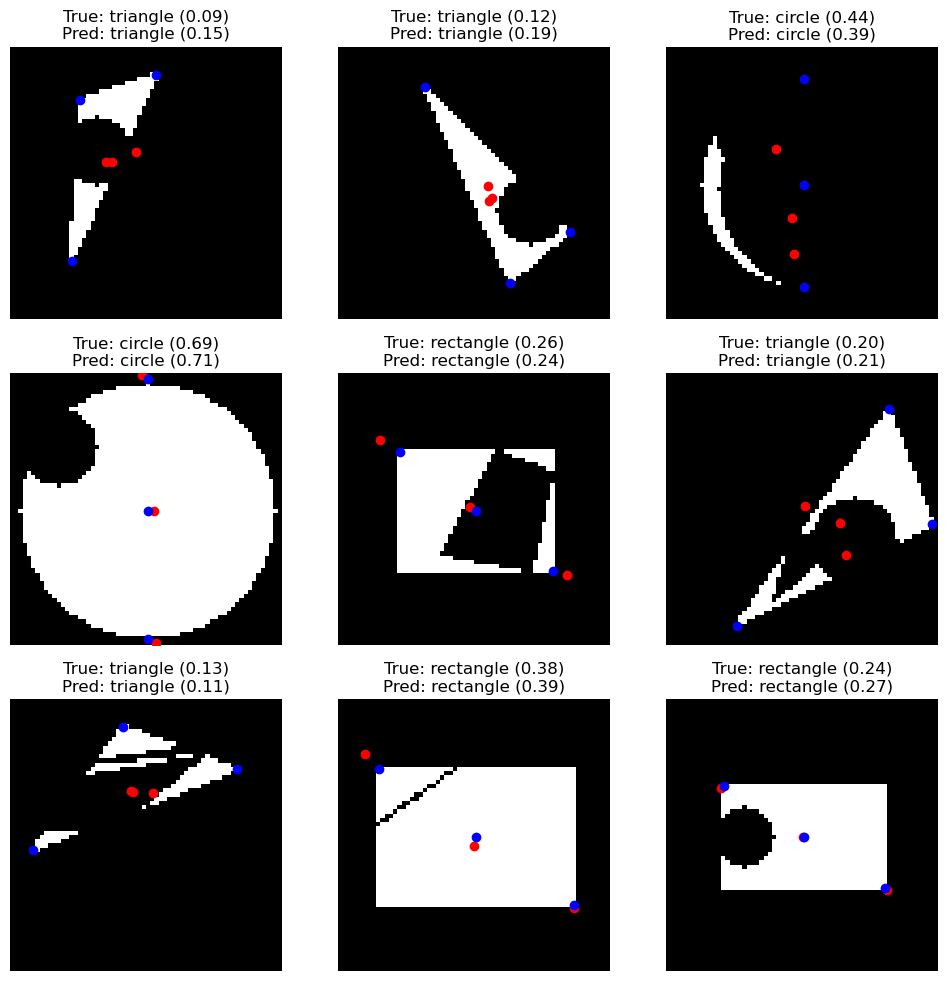

In [37]:
visualize_predictions(model, test_dataset)

In [38]:
# # Load the model
# model = ShapeModel().to(device)
# model.load_state_dict(torch.load("shape_model_2.pth"))
# model.eval()

# Export to ONNX
dummy_input = torch.randn(1, 1, 64, 64).to(device)
input_names = ['input']
output_names = ['shape_output', 'parameter_output']

# Try to export the model and catch any exceptions
try:
    torch.onnx.export(model, dummy_input, "shape_model_2.onnx", input_names=input_names, output_names=output_names)
    print("Model exported successfully.")
except Exception as e:
    print("Failed to export the model. Error:", str(e))

Model exported successfully.
